## _Part 1 - Guided Data Analysis_

In [192]:
import pandas as pd

In [193]:
import matplotlib.pyplot as plt

In [194]:
import seaborn as sns

In [195]:
df = pd.read_csv("titanic_train (1).csv")

In [196]:
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [197]:
# 3.Using the methods we learned, get to know the df:
# • Check for missing data in the columns
# • If there is missing data, does it make sense for these columns to have missing data? 
# How much data is missing? And will the lack of data affect  the analysis?



In [198]:
df.isnull().sum()


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [199]:
df.shape

(891, 12)

In [200]:
df.isnull().mean() * 100

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64

In [201]:
# 4.Delete the cabin column from the df

df.drop(columns="Cabin", inplace=True)

In [202]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Embarked'],
      dtype='object')

In [203]:
# 5. Update the missing values in the age column, for women, use the median value of all female passengers

df[df['Sex'] == 'female']['Age'].median()

27.0

In [204]:
df.loc[df['Sex'] == 'female', 'Age'] = df.loc[df['Sex'] == 'female', 'Age'].fillna(df[df['Sex'] == 'female']['Age'].median())

In [205]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            124
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked         2
dtype: int64

In [206]:
# 6. Update the missing values in the age column for men, use the median value of all male passengers

df[df['Sex'] == 'male']['Age'].median()

29.0

In [207]:
df.loc[df['Sex'] == 'male', 'Age'] = df.loc[df['Sex'] == 'male', 'Age'].fillna(df[df['Sex'] == 'male']['Age'].median())

In [208]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       2
dtype: int64

In [209]:
# 7. Fill in the missing value in the embarked column with the most commonly appearing value (the most repeated value in this column)

df['Embarked'].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [210]:
frequent_value = df["Embarked"].mode()[0] 

In [211]:
df['Embarked'] = df['Embarked'].fillna(frequent_value)

In [212]:
df['Embarked'].isnull().sum() 
# Am verificat daca mai sunt valori lipsa

np.int64(0)

In [213]:
# 8. Create a chart to show the distribution of passengers by gender.
# Choose a chart that suits you best, and design it so it is clear and presentable.

df['Sex'].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [214]:
gender = df['Sex'].value_counts()

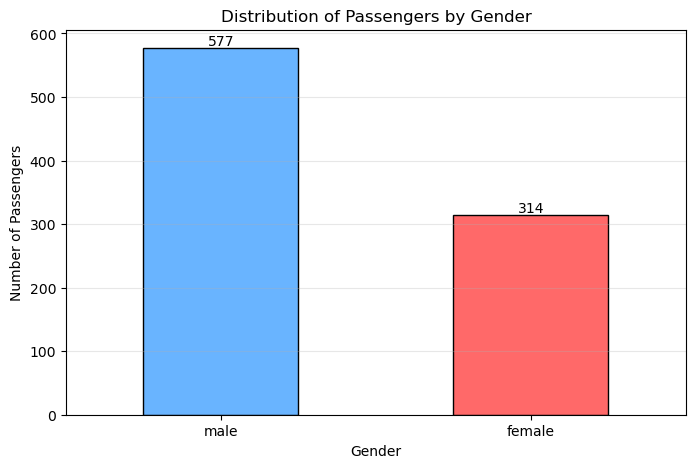

In [215]:
gender = df['Sex'].value_counts()

gender_plot = gender.plot.bar(
    figsize=(8,5),
    color=['#69B4FF', '#FF6969'],
    edgecolor='black'
)

gender_plot.bar_label(gender_plot.containers[0])

plt.title('Distribution of Passengers by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Passengers')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)


plt.show()

In [216]:
# 9. Create a chart to show the distribution of passengers by gender (Sex) and whether they survived (Survived)



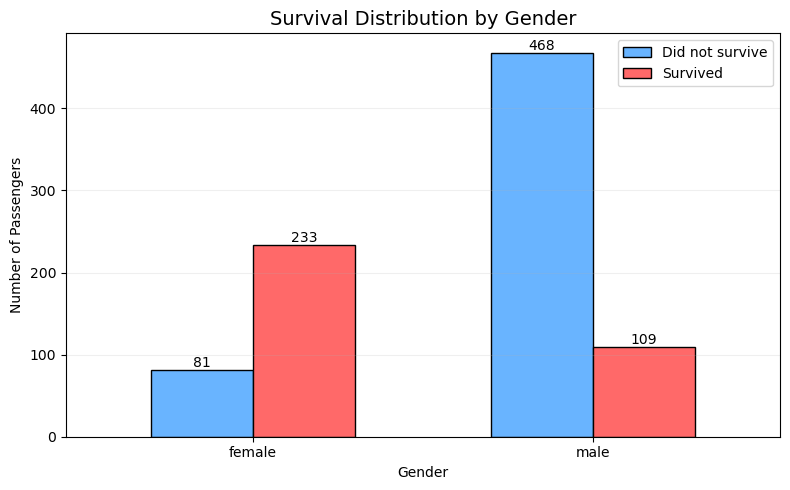

In [217]:
survival_gender = df.groupby(['Sex', 'Survived']).size().unstack()

plot = survival_gender.plot.bar(
    width=0.6,
    figsize=(8,5),
    color=['#69B4FF', '#FF6969'],
    edgecolor='black'
)

plot.bar_label(plot.containers[0])
plot.bar_label(plot.containers[1])

plt.title('Survival Distribution by Gender', fontsize=14)
plt.xlabel('Gender')
plt.ylabel('Number of Passengers')
plt.xticks(rotation=0)
plt.legend(['Did not survive', 'Survived'])
plt.grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.show()

In [218]:
#10. Use a displot chart to view the age distribution of passengers by age. Follow these guidelines:
#• Separate it into two charts according to the values in the gender column.
#• Within each chart, split the data into series according to the data in the survived column.
#• Set the display so that the data is stacked.

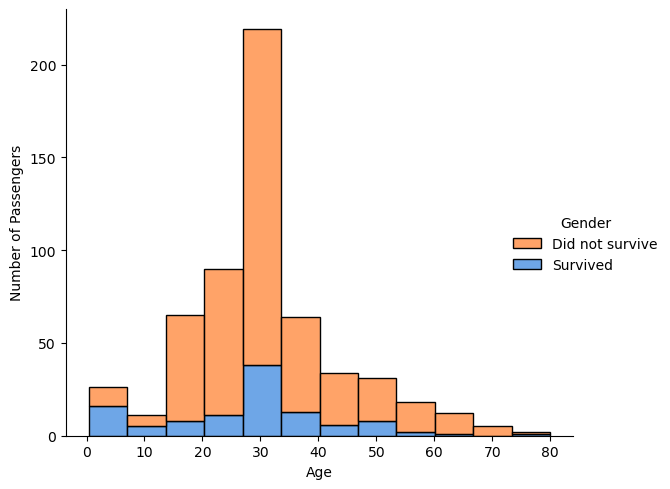

In [219]:
male = df[df['Sex'] == 'male']
age_plot = sns.displot(
    data=male,
    x='Age',
    hue='Survived',
    bins=12,
    multiple='stack',
    palette=['#FF8C42', '#4A90E2'],
    edgecolor='black',
    alpha=0.8,
    height=5,
    aspect=1.2
)

age_plot.set_axis_labels('Age', 'Number of Passengers')
age_plot.set_titles('Age Distribution - Male')

age_plot._legend.set_title('Gender')
for text, label in zip(age_plot._legend.texts, ['Did not survive', 'Survived']):
    text.set_text(label)

plt.show()

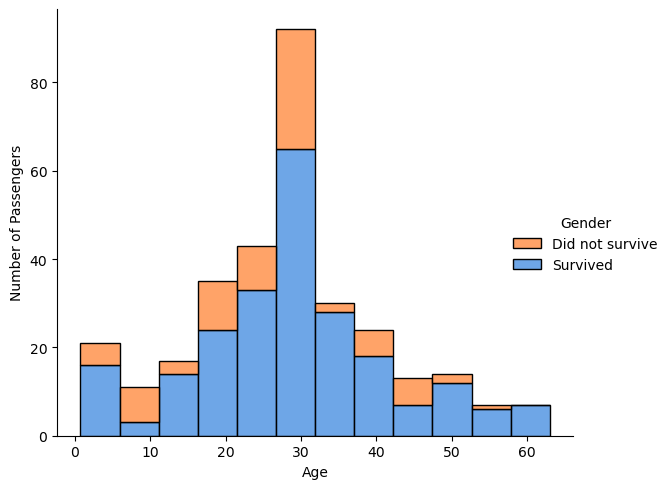

In [220]:
female = df[df['Sex'] == 'female']
age_plot = sns.displot(
    data=female,
    x='Age',
    hue='Survived',
    bins=12,
    multiple='stack',
    palette=['#FF8C42', '#4A90E2'],
    edgecolor='black',
    alpha=0.8,
    height=5,
    aspect=1.2
)

age_plot.set_axis_labels('Age', 'Number of Passengers')
age_plot.set_titles('Age Distribution - Female')

age_plot._legend.set_title('Gender')
for text, label in zip(age_plot._legend.texts, ['Did not survive', 'Survived']):
    text.set_text(label)

plt.show()

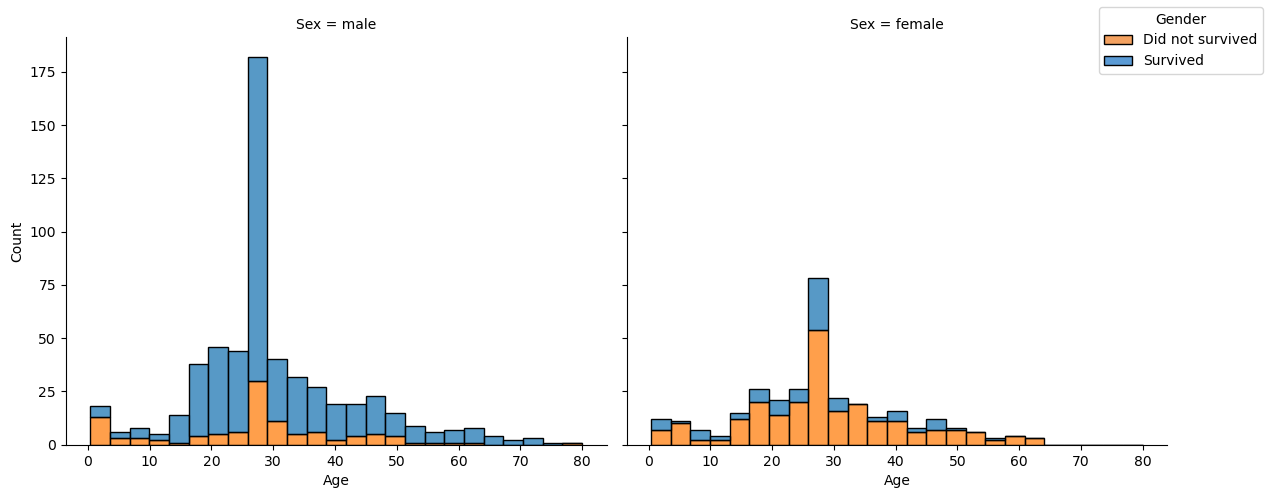

In [221]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

age_plot = sns.displot(
    data=df,
    x='Age',
    col='Sex',
    hue='Survived',
    multiple='stack',
    bins=25,
    edgecolor='black',
    height=5,
    aspect=1.2,

)

age_plot.set_axis_labels('Age', 'Count')
age_plot.set_titles('Sex = {col_name}')

age_plot.legend.remove()

legend = [
    Patch(facecolor='#F4A261', edgecolor='black', label='Did not survived'),
    Patch(facecolor='#5B9BD5', edgecolor='black', label='Survived')
]

age_plot.figure.legend(
    handles=legend,
    title='Gender',   
    loc='upper right'
)

plt.show()

In [222]:
#11. Now, examine whether there is a correlation between the different columns.
#To do this, select only the columns that have meaning (for example, the number of clients can vary, but this figure has no effect on the results of the
# analysis).
#Create a correlation table by applying the corr () method to the data. 
#Save the result in a variable named corr_mt it as you wish.
#Is there a strong positive correlation (values close to 1) or a negative correlation (values close to 1-) between any of the columns?

In [223]:
corr_data= df[['Survived','Age','SibSp', 'Parch', 'Fare', 'Pclass']]
corr_data.head()

,Survived,Age,SibSp,Parch,Fare,Pclass
0,0,22.0,1,0,7.2500,3
1,1,38.0,1,0,71.2833,1
2,1,26.0,0,0,7.9250,3
3,1,35.0,1,0,53.1000,1
4,0,35.0,0,0,8.0500,3


In [224]:
corr_mtx=corr_data.corr()
corr_mtx

,Survived,Age,SibSp,Parch,Fare,Pclass
Survived,1.000000,-0.073296,-0.035322,0.081629,0.257307,-0.338481
Age,-0.073296,1.000000,-0.236376,-0.176038,0.094161,-0.338056
SibSp,-0.035322,-0.236376,1.000000,0.414838,0.159651,0.083081
Parch,0.081629,-0.176038,0.414838,1.000000,0.216225,0.018443
Fare,0.257307,0.094161,0.159651,0.216225,1.000000,-0.549500
Pclass,-0.338481,-0.338056,0.083081,0.018443,-0.549500,1.000000


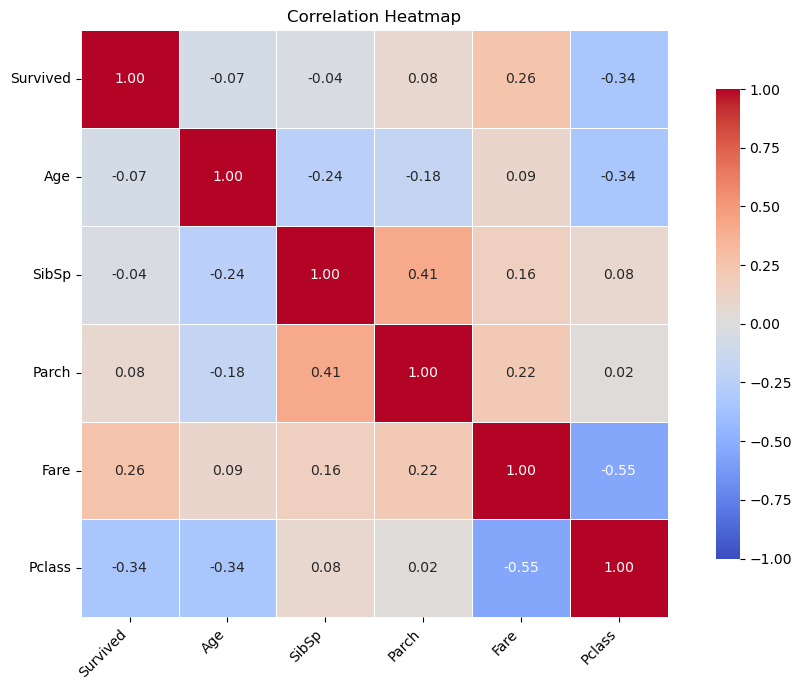

In [225]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_mtx,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    linecolor='white',
    square=True,
    cbar_kws={'shrink': 0.8},   
    vmin= -1, 
    vmax= 1
)

plt.title('Correlation Heatmap')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

#The heatmap shows the relationships between the numerical variables in the dataset. 
#The most important correlation with survival is Pclass (-0.34), suggesting that passengers from higher classes had a higher chance of survival. 
#Fare has a positive correlation of 0.26 with survival, while Age, SibSp, and Parch have very weak correlations with it.


## _Part 2 - Continued Analysis_



In [226]:
# 1.Did women have a higher change of survival than men? 

In [227]:
# Yes, the women had a higher survival chance than men, 74% compared to only 19% of men.

In [228]:
df.groupby('Sex')['Survived'].mean().mul(100).round().astype(int).astype(str) + '%'


Sex
female    74%
male      19%
Name: Survived, dtype: object

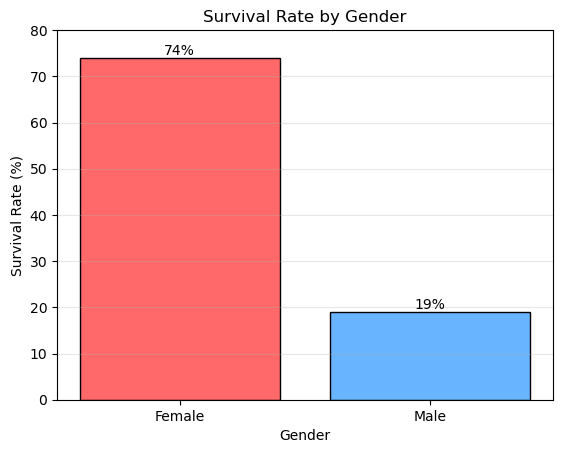

In [229]:
survival = [74, 19]
labels = ['Female', 'Male']
colors = ['#FF6969', '#69B4FF']

plot = plt.bar(
    labels,
    survival,
    color=colors,
    edgecolor='black'
)

plt.bar_label(plot, labels=['74%', '19%'])

plt.title('Survival Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Survival Rate (%)')
plt.ylim(0, 80)
plt.grid(axis='y', alpha=0.3)

plt.show()

In [230]:
# 2.Did age influenced the chance of survival?

In [231]:
# Yes, the age had influenced the chance of survival.Children had the highest survival rate (50%), and the lowest the seniors (23%).

In [232]:
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[0, 18, 40, 60, 100],
    labels=['Child', 'Young Adult', 'Adult', 'Senior']
)

df.groupby('AgeGroup', observed=True)['Survived'].mean().mul(100).round().astype(int).astype(str) + '%'

AgeGroup
Child          50%
Young Adult    36%
Adult          39%
Senior         23%
Name: Survived, dtype: object

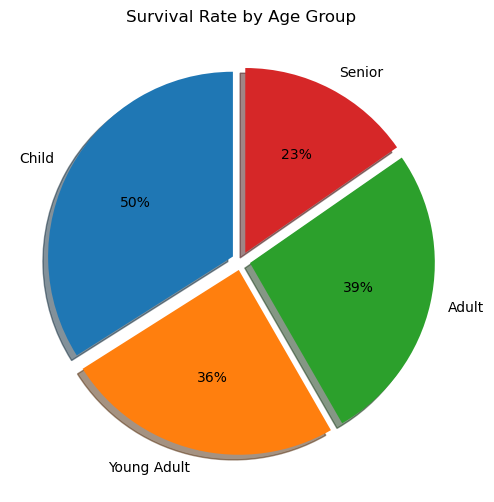

In [233]:
survival_age = df.groupby('AgeGroup', observed=True)['Survived'].mean() * 100

values = ['50%', '36%', '39%', '23%']

survival_age.plot.pie(
    autopct=lambda p: values.pop(0),
    startangle=90,
    figsize=(6,6),
    ylabel='',
    labels=survival_age.index,
    explode=(0.05, 0.05, 0.05, 0.05),
    shadow=True
)

plt.title('Survival Rate by Age Group')
plt.show()

In [234]:
# 3.Did passengers in higher classes have a higher chance of survival? 

In [235]:
#Yes, passengers in higher claseses had a higher chance of survival. First class passengers had the highset survival rate (63%),folowed by second class (47%) and third class (24%).


In [236]:
df.groupby('Pclass')['Survived'].mean().mul(100).round().astype(int).astype(str) + '%'

Pclass
1    63%
2    47%
3    24%
Name: Survived, dtype: object

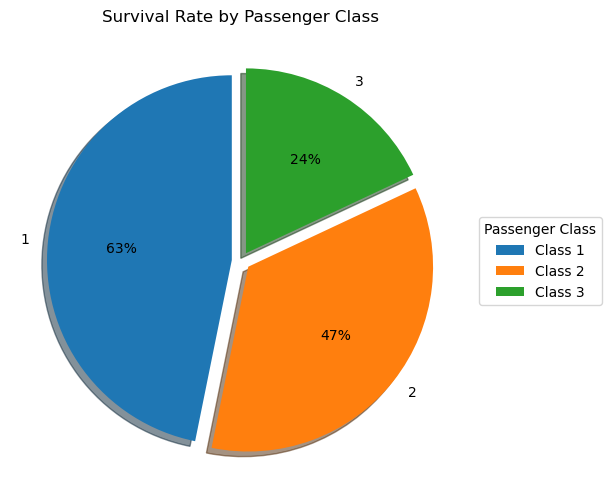

In [237]:
survival_class = df.groupby('Pclass')['Survived'].mean() * 100

values = ['63%', '47%', '24%']

survival_class.plot.pie(
    autopct=lambda p: values.pop(0),
    startangle=90,
    figsize=(6,6),
    ylabel='',
    labels=survival_class.index,
    explode=(0.05, 0.05, 0.05),
    shadow=True
)
plt.legend(
    ['Class 1', 'Class 2', 'Class 3'],
    title='Passenger Class',
    loc='center left',
    bbox_to_anchor=(1, 0.5)
)

plt.title('Survival Rate by Passenger Class')
plt.show()